# 01 — NBA Player Tracking & 2D Court Mapping

## Obiettivo

Questo notebook implementa la prima pipeline di Computer Vision per l'analisi di video televisivi NBA.

Il sistema utilizza **YOLO11** per rilevare i giocatori, **SAM2** per il tracking e la segmentazione, e un modello di **Court Keypoint Detection** per individuare i riferimenti geometrici del campo.

Attraverso una trasformazione prospettica (*omografia*) stimata con RANSAC, le posizioni dei giocatori vengono proiettate su una rappresentazione bidimensionale del campo NBA.

### Pipeline

Video NBA → Player Detection → Non-Maximum Suppression → SAM2 Tracking → Court Keypoint Detection → Homography → Player Position Mapping → Video 2D e CSV.

### Tecnologie principali

Python, PyTorch, YOLO11, SAM2, OpenCV, Roboflow Inference, Supervision e Sports.

### Output

- Video originale annotato con maschere e identificativi dei giocatori.
- Coordinate temporali dei giocatori espresse nel sistema di riferimento del campo.
- Video della mappa bidimensionale animata.
- File CSV per la diagnostica della geometria e delle posizioni.

**Nota metodologica:** il notebook costituisce una baseline sperimentale. Le coordinate prodotte sono stime e richiedono una successiva validazione quantitativa attraverso annotazioni indipendenti.
**Verifica architetturale (12/10/2026):** per l’identificativo `basketball-player-detection-3-ycjdo/4`, la funzione `get_model_type` di Roboflow Inference ha restituito `task=object-detection` e `model_type=yolov11`. Pertanto il detector usato nella baseline appartiene alla famiglia **YOLO11**, non a RF-DETR. La variante dimensionale (ad esempio Small) non è verificata da questo controllo. Il modello separato di keypoint del campo (`basketball-court-detection-2/14`) non viene identificato automaticamente come YOLO11 da tale verifica.


### 1. Verifica dell'ambiente Python e GPU

In [ ]:
import sys
import torch

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("GPU disponibile:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    raise RuntimeError(
        "Attiva una GPU dalle impostazioni del runtime, "
        "poi esegui nuovamente questa cella."
    )

Python: 3.13.15
PyTorch: 2.14.1+cu130
GPU disponibile: True
GPU: Tesla T4


### 2. Collegamento a Google Drive

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 16. Installazione di Supervision e Sports

In [ ]:
%pip install -q "supervision==0.27.0" "git+https://github.com/roboflow/sports.git@feat/basketball"

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 212.4/212.4 kB 11.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
inference-gpu 1.7.4 requires supervision<0.31.0,>=0.30.6, but you have supervision 0.27.0 which is incompatible.
inference-models 0.39.3 requires supervision>=0.29.0, but you have supervision 0.27.0 which is incompatible.
streamvision 0.1.1 requires supervision<0.31.0,>=0.30.6, but you have supervision 0.27.0 which is incompatible.
roboflow-workflows 0.2.6 requires supervision<0.31.0,>=0.30.6, but you have supervision 0.27.0 which is incompatible.


### 17. Pulizia delle maschere SAM2

In [ ]:
import supervision as sv
import numpy as np
import cv2

def draw_tracks(frame, object_ids, mask_logits, frame_index):
    annotated = frame.copy()
    rows = []

    masks = (mask_logits > 0).detach().cpu().numpy()

    if masks.ndim == 4:
        masks = masks[:, 0]

    for object_id, mask in zip(object_ids, masks):
        object_id = int(object_id)
        mask = mask.astype(bool)

        if mask.any():
            clean_mask = sv.filter_segments_by_distance(
                mask,
                relative_distance=0.03,
                mode="edge",
            ).astype(bool)
        else:
            clean_mask = mask

        ys, xs = np.where(clean_mask)

        if len(xs) == 0:
            rows.append([
                frame_index, object_id, 0,
                "", "", "", "", "", "",
            ])
            continue

        x1, y1 = int(xs.min()), int(ys.min())
        x2, y2 = int(xs.max()), int(ys.max())
        area = int(clean_mask.sum())

        color = (
            (0, 255, 255) if object_id % 2 else (255, 200, 0)
        )

        annotated[clean_mask] = (
            0.75 * annotated[clean_mask]
            + 0.25 * np.array(color)
        ).astype(np.uint8)

        cv2.rectangle(
            annotated, (x1, y1), (x2, y2), color, 2
        )

        position = (x1, max(25, y1 - 8))
        for text_color, thickness in [((0, 0, 0), 5), (color, 2)]:
            cv2.putText(
                annotated, f"ID {object_id}", position,
                cv2.FONT_HERSHEY_SIMPLEX, 0.75,
                text_color, thickness,
            )

        foot_x = (x1 + x2) / 2
        foot_y = float(y2)

        rows.append([
            frame_index, object_id, area,
            x1, y1, x2, y2, foot_x, foot_y,
        ])

    return annotated, rows

print("Pulizia delle maschere aggiornata.")

Pulizia delle maschere aggiornata.


### 3. Creazione delle cartelle e della configurazione del progetto

In [ ]:
from pathlib import Path
import json
from datetime import datetime, timezone

PROJECT_DIR = Path("/content/drive/MyDrive/NBA_Tracking_Project")

folders = [
    "videos",
    "outputs",
    "models",
    "annotations",
    "configs",
]

for folder in folders:
    (PROJECT_DIR / folder).mkdir(parents=True, exist_ok=True)

# Directory temporanea locale: utile per elaborare i video.
WORK_DIR = Path("/content/nba_tracking_work")
WORK_DIR.mkdir(parents=True, exist_ok=True)

config_path = PROJECT_DIR / "configs" / "baseline.json"

# Preserva una configurazione già esistente.
if not config_path.exists():
    config = {
        "created_at": datetime.now(timezone.utc).isoformat(),
        "domain": "NBA",
        "player_model_id": "basketball-player-detection-3-ycjdo/4",
        "court_model_id": "basketball-court-detection-2/14",
        "goal": "Player tracking and projection onto a 2D court",
    }

    config_path.write_text(
        json.dumps(config, indent=2),
        encoding="utf-8",
    )

print("Progetto:", PROJECT_DIR)
print("Cartelle:")
for folder in folders:
    print(" •", folder)

print("\nConfigurazione:")
print(config_path.read_text(encoding="utf-8"))

Progetto: /content/drive/MyDrive/NBA_Tracking_Project
Cartelle:
 • videos
 • outputs
 • models
 • annotations
 • configs

Configurazione:
{
  "created_at": "2026-10-10T12:56:21.005791+00:00",
  "domain": "NBA",
  "player_model_id": "basketball-player-detection-3-ycjdo/4",
  "court_model_id": "basketball-court-detection-2/14",
  "goal": "Player tracking and projection onto a 2D court"
}


### 4. Caricamento del video NBA nell'ambiente di lavoro

In [ ]:
from pathlib import Path
import shutil

PROJECT_DIR = Path("/content/drive/MyDrive/NBA_Tracking_Project")
WORK_DIR = Path("/content/nba_tracking_work")
WORK_DIR.mkdir(parents=True, exist_ok=True)

VIDEO_NAME = "boston-celtics-new-york-knicks-game-1-q2-08.09-08.03.mp4"

DRIVE_VIDEO_PATH = PROJECT_DIR / "videos" / VIDEO_NAME
VIDEO_PATH = WORK_DIR / VIDEO_NAME

if not DRIVE_VIDEO_PATH.is_file():
    available = [
        p.name for p in (PROJECT_DIR / "videos").glob("*")
        if p.is_file()
    ]
    raise FileNotFoundError(
        f"Video non trovato: {DRIVE_VIDEO_PATH}\n"
        f"File presenti: {available}"
    )

shutil.copy2(DRIVE_VIDEO_PATH, VIDEO_PATH)

print("Video:", VIDEO_PATH.name)
print(f"Dimensione: {VIDEO_PATH.stat().st_size / 1_000_000:.2f} MB")

Video: boston-celtics-new-york-knicks-game-1-q2-08.09-08.03.mp4
Dimensione: 7.32 MB


### 5. Verifica delle proprietà e dell'integrità del video

In [ ]:
import cv2
import math

cap = cv2.VideoCapture(str(VIDEO_PATH))

if not cap.isOpened():
    raise RuntimeError("Impossibile aprire il video.")

fps = cap.get(cv2.CAP_PROP_FPS)
declared_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

read_frames = 0

try:
    while True:
        success, frame = cap.read()
        if not success:
            break
        read_frames += 1
finally:
    cap.release()

print(f"Risoluzione: {width} × {height}")
print(f"FPS: {fps:.3f}")
print(f"Frame dichiarati: {declared_frames}")
print(f"Frame effettivamente letti: {read_frames}")

if read_frames == 0:
    raise RuntimeError("Non è stato possibile leggere alcun fotogramma.")

if math.isfinite(fps) and fps > 0:
    print(f"Durata stimata dai frame letti: {read_frames / fps:.2f} secondi")

if read_frames == declared_frames:
    print("\nOK: conteggio dei frame letti coerente con i metadati.")
else:
    print(
        "\nATTENZIONE: conteggi diversi. Prima di procedere "
        "controlliamo se dipende dai metadati o dalla decodifica."
    )

Risoluzione: 1920 × 1080
FPS: 30.000
Frame dichiarati: 165
Frame effettivamente letti: 165
Durata stimata dai frame letti: 5.50 secondi

OK: conteggio dei frame letti coerente con i metadati.


### 6. Visualizzazione di alcuni fotogrammi della sequenza

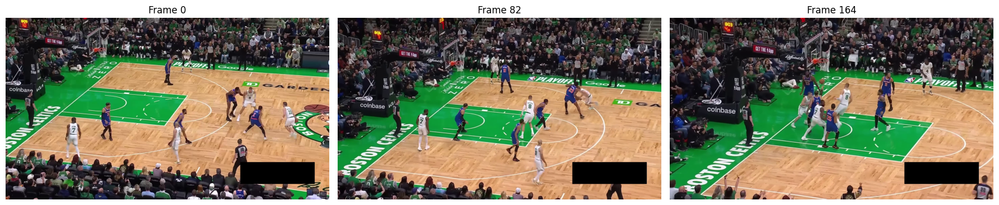

In [ ]:
import matplotlib.pyplot as plt

targets = sorted(set([0, read_frames // 2, read_frames - 1]))
samples = {}

cap = cv2.VideoCapture(str(VIDEO_PATH))

try:
    for index in range(read_frames):
        success, frame = cap.read()
        if not success:
            break

        if index in targets:
            samples[index] = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
finally:
    cap.release()

if len(samples) != len(targets):
    raise RuntimeError(
        f"Seconda lettura incompleta: trovati {list(samples)}, "
        f"richiesti {targets}."
    )

fig, axes = plt.subplots(
    1, len(targets),
    figsize=(18, 5),
    squeeze=False,
)

for ax, index in zip(axes[0], targets):
    ax.imshow(samples[index])
    ax.set_title(f"Frame {index}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### 7. Installazione della libreria Roboflow Inference

In [ ]:
%pip install -q inference-gpu

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.7/105.7 kB 9.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.6/68.6 kB 7.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.6/56.6 kB 6.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 12.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.4/99.4 kB 8.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.8/46.8 kB 4.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 4.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10

### 8. Verifica della libreria Pillow

In [ ]:
import PIL
from PIL import Image, ImageFont, ImageText

print("Pillow:", PIL.__version__)
print("Import delle librerie immagini riuscito.")

Pillow: 12.3.0
Import delle librerie immagini riuscito.


### 9. Caricamento del modello YOLO11 preaddestrato (Roboflow Inference)

In [ ]:
import os
from getpass import getpass

api_key = getpass("Incolla qui la tua API key Roboflow: ").strip()

if not api_key:
    raise ValueError("API key non inserita.")

os.environ["ROBOFLOW_API_KEY"] = api_key
del api_key

from inference import get_model

PLAYER_MODEL_ID = "basketball-player-detection-3-ycjdo/4"

player_model = get_model(model_id=PLAYER_MODEL_ID)

print("Modello caricato:", PLAYER_MODEL_ID)

Incolla qui la tua API key Roboflow: ··········


/usr/local/lib/python3.13/dist-packages/inference/core/env.py:345: InferenceDeprecationWarning: CORE_MODEL_GAZE_ENABLED is True: POST /gaze/gaze_detection is registered as a deprecation stub returning HTTP 410 Gone. The stub and this flag will be removed end of Q2 2026. Set CORE_MODEL_GAZE_ENABLED=False to disable it now.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
[transformers] `DepthProImageProcessorFast` is deprecated. The `Fast` suffix for image processors has been removed; use `DepthProImageProcessor` instead.
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/infer

Output()

Modello caricato: basketball-player-detection-3-ycjdo/4


### 10. Rilevamento dei giocatori nel primo fotogramma

Tutte le classi rilevate:
{'player': 10, 'referee': 4, 'player-in-possession': 1, 'number': 6, 'rim': 1, 'ball': 1}

Giocatori rilevati: 11


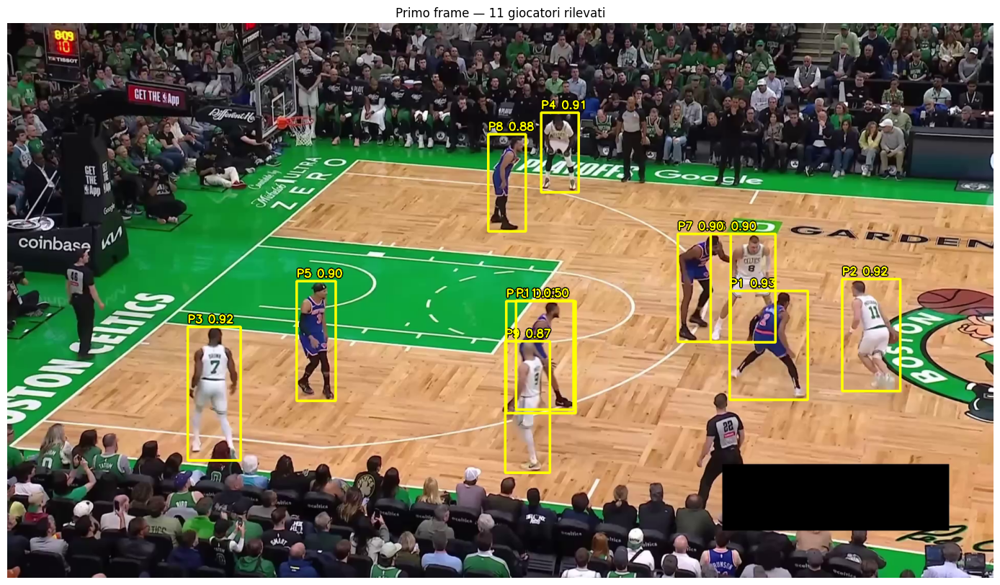

Immagine salvata: /content/drive/MyDrive/NBA_Tracking_Project/outputs/01_first_frame_detection.jpg


In [ ]:
import cv2
import matplotlib.pyplot as plt
from collections import Counter

cap = cv2.VideoCapture(str(VIDEO_PATH))
success, first_frame = cap.read()
cap.release()

if not success:
    raise RuntimeError("Impossibile leggere il primo frame.")

result = player_model.infer(
    first_frame,
    confidence=0.4,
    iou_threshold=0.9,
)[0]

PLAYER_CLASSES = {
    "player",
    "player-in-possession",
    "player-jump-shot",
    "player-layup-dunk",
    "player-shot-block",
}

player_predictions = [
    prediction
    for prediction in result.predictions
    if prediction.class_name in PLAYER_CLASSES
]

print("Tutte le classi rilevate:")
print(dict(Counter(p.class_name for p in result.predictions)))
print("\nGiocatori rilevati:", len(player_predictions))

annotated_frame = first_frame.copy()
height, width = annotated_frame.shape[:2]

for index, prediction in enumerate(player_predictions, start=1):
    x1 = max(0, int(prediction.x - prediction.width / 2))
    y1 = max(0, int(prediction.y - prediction.height / 2))
    x2 = min(width - 1, int(prediction.x + prediction.width / 2))
    y2 = min(height - 1, int(prediction.y + prediction.height / 2))

    # Giallo con testo nero, per mantenere le etichette leggibili.
    color = (0, 255, 255)
    label = f"P{index} {prediction.confidence:.2f}"

    cv2.rectangle(annotated_frame, (x1, y1), (x2, y2), color, 3)

    text_y = max(25, y1 - 8)
    cv2.putText(
        annotated_frame, label, (x1, text_y),
        cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 0), 5,
    )
    cv2.putText(
        annotated_frame, label, (x1, text_y),
        cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, 2,
    )

plt.figure(figsize=(18, 10))
plt.imshow(cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title(f"Primo frame — {len(player_predictions)} giocatori rilevati")
plt.show()

output_dir = PROJECT_DIR / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / "01_first_frame_detection.jpg"

if not cv2.imwrite(str(output_path), annotated_frame):
    raise RuntimeError("Salvataggio dell'immagine non riuscito.")

print("Immagine salvata:", output_path)

### 11. Rimozione delle detection duplicate mediante NMS

In [ ]:
import numpy as np

# Coordinate e confidenze dei rilevamenti già ottenuti.
boxes = np.array([
    [
        p.x - p.width / 2,
        p.y - p.height / 2,
        p.x + p.width / 2,
        p.y + p.height / 2,
    ]
    for p in player_predictions
], dtype=np.float32).reshape(-1, 4)

scores = np.array([
    p.confidence for p in player_predictions
], dtype=np.float32)


def remove_duplicate_boxes(boxes, scores, iou_threshold=0.70):
    order = np.argsort(-scores)
    keep = []

    while len(order):
        current = int(order[0])
        keep.append(current)
        remaining = order[1:]

        if not len(remaining):
            break

        top_left = np.maximum(boxes[current, :2], boxes[remaining, :2])
        bottom_right = np.minimum(boxes[current, 2:], boxes[remaining, 2:])

        intersection = np.prod(
            np.maximum(bottom_right - top_left, 0), axis=1
        )

        current_area = np.prod(
            np.maximum(boxes[current, 2:] - boxes[current, :2], 0)
        )
        remaining_areas = np.prod(
            np.maximum(boxes[remaining, 2:] - boxes[remaining, :2], 0),
            axis=1,
        )

        union = current_area + remaining_areas - intersection
        iou = intersection / np.maximum(union, 1e-8)

        order = remaining[iou <= iou_threshold]

    return np.array(keep, dtype=int)


keep_indices = remove_duplicate_boxes(boxes, scores)

initial_boxes = boxes[keep_indices]
initial_scores = scores[keep_indices]

print("Prima:", len(boxes))
print("Dopo:", len(initial_boxes))
print("Etichette originali rimosse:", [
    f"P{i + 1}" for i in range(len(boxes))
    if i not in set(keep_indices.tolist())
])

Prima: 11
Dopo: 10
Etichette originali rimosse: ['P11']


### 12. Visualizzazione delle bounding box iniziali

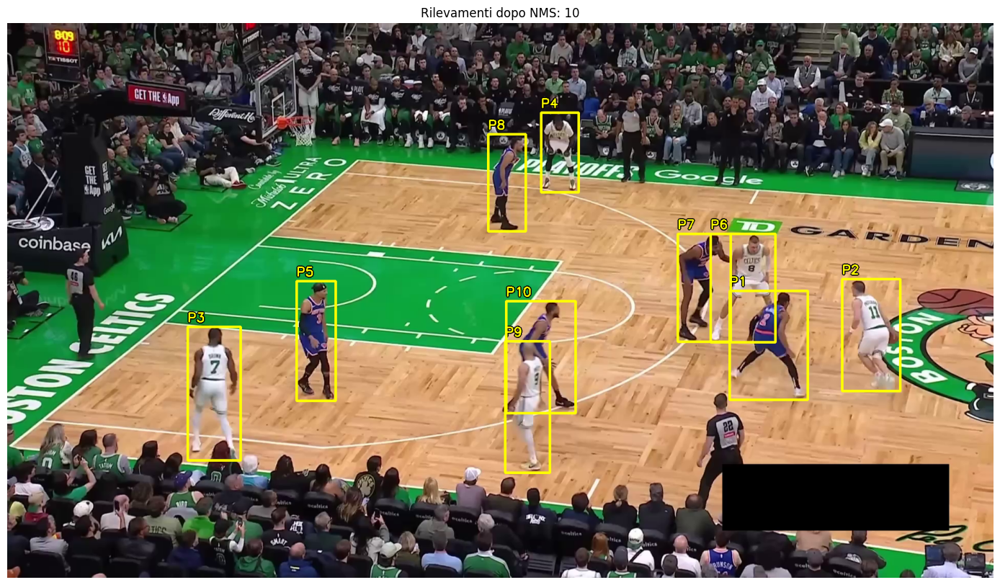

In [ ]:
clean_frame = first_frame.copy()

for index, box in enumerate(initial_boxes, start=1):
    x1, y1, x2, y2 = np.rint(box).astype(int)

    cv2.rectangle(
        clean_frame, (x1, y1), (x2, y2),
        (0, 255, 255), 3,
    )

    label = f"P{index}"
    position = (x1, max(25, y1 - 10))

    for color, thickness in [((0, 0, 0), 5), ((0, 255, 255), 2)]:
        cv2.putText(
            clean_frame, label, position,
            cv2.FONT_HERSHEY_SIMPLEX, 0.8, color, thickness,
        )

plt.figure(figsize=(18, 10))
plt.imshow(cv2.cvtColor(clean_frame, cv2.COLOR_BGR2RGB))
plt.title(f"Rilevamenti dopo NMS: {len(initial_boxes)}")
plt.axis("off")
plt.show()

### 13. Salvataggio delle detection per l'inizializzazione del tracking

In [ ]:
import numpy as np

INITIAL_DETECTIONS_PATH = (
    PROJECT_DIR / "outputs" / f"{VIDEO_PATH.stem}_initial_detections.npz"
)

np.savez(
    INITIAL_DETECTIONS_PATH,
    boxes=initial_boxes,
    scores=initial_scores,
    video_name=VIDEO_PATH.name,
)

print("Rilevamenti salvati:", INITIAL_DETECTIONS_PATH)

Rilevamenti salvati: /content/drive/MyDrive/NBA_Tracking_Project/outputs/boston-celtics-new-york-knicks-game-1-q2-08.09-08.03_initial_detections.npz


### 14. Installazione del repository SAM2

In [ ]:
import subprocess
import sys
from pathlib import Path

SAM2_DIR = Path("/content/segment-anything-2-real-time")

if not SAM2_DIR.exists():
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/Gy920/segment-anything-2-real-time.git",
            str(SAM2_DIR),
        ],
        check=True,
    )

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-e", str(SAM2_DIR)],
    check=True,
)

commit = subprocess.check_output(
    ["git", "-C", str(SAM2_DIR), "rev-parse", "HEAD"],
    text=True,
).strip()

(PROJECT_DIR / "configs" / "sam2_commit.txt").write_text(commit)

print("\nInstallazione terminata.")
print("Versione del repository:", commit)


Installazione terminata.
Versione del repository: e3623cda3f748df999f76db663f08da7a884a820


### 15. Caricamento del modello SAM2 e inizializzazione del predictor

In [ ]:
import os
import sys
import importlib
from pathlib import Path
import torch

SAM2_DIR = Path("/content/segment-anything-2-real-time")
SAM2_CHECKPOINT = SAM2_DIR / "checkpoints" / "sam2.1_hiera_large.pt"

if not SAM2_CHECKPOINT.is_file():
    raise FileNotFoundError(f"Checkpoint non trovato: {SAM2_CHECKPOINT}")

# Metti il repository del tutorial al PRIMO posto.
repo_path = str(SAM2_DIR)
sys.path = [repo_path] + [
    path for path in sys.path if path != repo_path
]

# Rimuovi dalla cache gli import della precedente versione di SAM2.
for module_name in list(sys.modules):
    if module_name == "sam2" or module_name.startswith("sam2."):
        del sys.modules[module_name]

importlib.invalidate_caches()
os.chdir(SAM2_DIR)

import sam2
import sam2.build_sam as sam2_builder

print("SAM2 importato da:", sam2.__file__)
print("Builder importato da:", sam2_builder.__file__)

if not hasattr(sam2_builder, "build_sam2_camera_predictor"):
    raise ImportError(
        "La versione importata non contiene il camera predictor."
    )

if not torch.cuda.is_available():
    raise RuntimeError("Attiva la GPU prima di caricare SAM2.")

predictor = sam2_builder.build_sam2_camera_predictor(
    "configs/sam2.1/sam2.1_hiera_l.yaml",
    str(SAM2_CHECKPOINT),
    device="cuda",
)

print("\nSAM2 caricato.")
print("GPU:", torch.cuda.get_device_name(0))

SAM2 importato da: /content/segment-anything-2-real-time/sam2/__init__.py
Builder importato da: /content/segment-anything-2-real-time/sam2/build_sam.py

SAM2 caricato.
GPU: Tesla T4


### 18. Tracking dei giocatori con SAM2

In [ ]:
from tqdm.auto import tqdm
import torch

AMP_DTYPE = (
    torch.bfloat16
    if torch.cuda.is_bf16_supported()
    else torch.float16
)

# Recupera i rettangoli salvati.
with np.load(INITIAL_DETECTIONS_PATH) as saved:
    initial_boxes = saved["boxes"].astype(np.float32)

RAW_TRACKING_PATH = WORK_DIR / f"{VIDEO_PATH.stem}_tracking_raw.mp4"
TRACKS_CSV_PATH = (
    PROJECT_DIR / "outputs" / f"{VIDEO_PATH.stem}_tracks.csv"
)

cap = cv2.VideoCapture(str(VIDEO_PATH))
success, frame = cap.read()

if not success:
    cap.release()
    raise RuntimeError("Impossibile leggere il primo frame.")

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
height, width = frame.shape[:2]

writer = cv2.VideoWriter(
    str(RAW_TRACKING_PATH),
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (width, height),
)

if not writer.isOpened():
    cap.release()
    raise RuntimeError("Impossibile creare il video di output.")

processed_frames = 0

try:
    with (
        open(TRACKS_CSV_PATH, "w", newline="") as csv_file,
        torch.inference_mode(),
        torch.autocast("cuda", dtype=AMP_DTYPE),
        tqdm(total=total_frames, desc="Tracking") as progress,
    ):
        csv_writer = csv.writer(csv_file)
        csv_writer.writerow([
            "frame", "track_id", "mask_area_px",
            "x1", "y1", "x2", "y2", "foot_x", "foot_y",
        ])

        # Inizializza una nuova sequenza.
        predictor.frame_idx = 0
        predictor.load_first_frame(
            cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        )

        for object_id, box in enumerate(initial_boxes, start=1):
            _, object_ids, mask_logits = predictor.add_new_prompt(
                frame_idx=0,
                obj_id=object_id,
                bbox=box.reshape(1, 4),
            )

        annotated, rows = draw_tracks(
            frame, object_ids, mask_logits, frame_index=0
        )
        writer.write(annotated)
        csv_writer.writerows(rows)
        processed_frames = 1
        progress.update(1)

        while True:
            success, frame = cap.read()
            if not success:
                break

            object_ids, mask_logits = predictor.track(
                cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            )

            annotated, rows = draw_tracks(
                frame, object_ids, mask_logits,
                frame_index=processed_frames,
            )

            writer.write(annotated)
            csv_writer.writerows(rows)

            processed_frames += 1
            progress.update(1)

finally:
    cap.release()
    writer.release()

print("Frame elaborati:", processed_frames, "/", total_frames)
print("Coordinate salvate:", TRACKS_CSV_PATH)

Tracking:   0%|          | 0/165 [00:00<?, ?it/s]

Frame elaborati: 165 / 165
Coordinate salvate: /content/drive/MyDrive/NBA_Tracking_Project/outputs/boston-celtics-new-york-knicks-game-1-q2-08.09-08.03_tracks.csv


### 19. Esportazione del video di tracking

In [ ]:
from IPython.display import Video, display

LOCAL_TRACKING_PATH = WORK_DIR / f"{VIDEO_PATH.stem}_tracking.mp4"
FINAL_TRACKING_PATH = (
    PROJECT_DIR / "outputs" / LOCAL_TRACKING_PATH.name
)

conversion = subprocess.run(
    [
        "ffmpeg", "-y", "-loglevel", "error",
        "-i", str(RAW_TRACKING_PATH),
        "-c:v", "libx264", "-crf", "23",
        "-pix_fmt", "yuv420p",
        "-movflags", "+faststart",
        str(LOCAL_TRACKING_PATH),
    ],
    capture_output=True,
    text=True,
)

if conversion.returncode != 0:
    raise RuntimeError(conversion.stderr)

shutil.copy2(LOCAL_TRACKING_PATH, FINAL_TRACKING_PATH)

print("Video salvato:", FINAL_TRACKING_PATH)
display(Video(str(LOCAL_TRACKING_PATH), embed=True, width=1100))

Video salvato: /content/drive/MyDrive/NBA_Tracking_Project/outputs/boston-celtics-new-york-knicks-game-1-q2-08.09-08.03_tracking.mp4


### 20. Caricamento del modello del campo

In [ ]:
from inference import get_model

COURT_MODEL_ID = "basketball-court-detection-2/14"

court_model = get_model(model_id=COURT_MODEL_ID)

print("Modello del campo caricato:", COURT_MODEL_ID)

Output()

Modello del campo caricato: basketball-court-detection-2/14


### 21. Rilevamento dei keypoint del campo

Campi rilevati: 1
Punti totali restituiti: 33
Punti sopra soglia: 12
Punto 0: x=687.0, y=269.0, confidenza=1.00
Punto 1: x=657.0, y=292.0, confidenza=1.00
Punto 2: x=508.0, y=412.0, confidenza=0.99
Punto 3: x=298.0, y=580.0, confidenza=0.94
Punto 6: x=548.0, y=499.0, confidenza=0.99
Punto 7: x=1046.0, y=324.0, confidenza=1.00
Punto 8: x=604.0, y=827.0, confidenza=0.84
Punto 9: x=1082.0, y=464.0, confidenza=1.00
Punto 10: x=1018.0, y=544.0, confidenza=1.00
Punto 11: x=942.0, y=644.0, confidenza=1.00
Punto 12: x=1469.0, y=329.0, confidenza=0.99
Punto 13: x=1355.0, y=578.0, confidenza=1.00


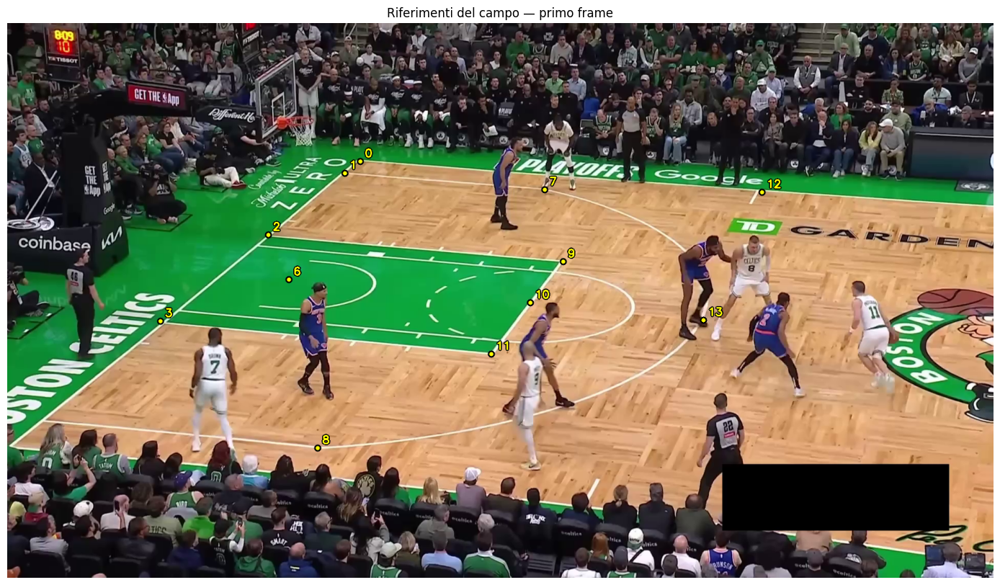

Immagine salvata: /content/drive/MyDrive/NBA_Tracking_Project/outputs/02_court_keypoints.jpg


In [ ]:
import cv2
import matplotlib.pyplot as plt

cap = cv2.VideoCapture(str(VIDEO_PATH))
success, court_frame = cap.read()
cap.release()

if not success:
    raise RuntimeError("Impossibile leggere il primo frame.")

court_result = court_model.infer(
    court_frame,
    confidence=0.3,
)[0]

print("Campi rilevati:", len(court_result.predictions))

if not court_result.predictions:
    raise RuntimeError("Il modello non ha rilevato il campo.")

court_prediction = max(
    court_result.predictions,
    key=lambda prediction: prediction.confidence,
)

KEYPOINT_THRESHOLD = 0.5

visible_keypoints = [
    point
    for point in court_prediction.keypoints
    if point.confidence >= KEYPOINT_THRESHOLD
]

print("Punti totali restituiti:", len(court_prediction.keypoints))
print("Punti sopra soglia:", len(visible_keypoints))

annotated_court = court_frame.copy()

for point in visible_keypoints:
    position = (round(point.x), round(point.y))
    label = str(point.class_id)

    cv2.circle(annotated_court, position, 7, (0, 0, 0), -1)
    cv2.circle(annotated_court, position, 4, (0, 255, 255), -1)

    text_position = (position[0] + 9, position[1] - 9)

    for color, thickness in [((0, 0, 0), 5), ((0, 255, 255), 2)]:
        cv2.putText(
            annotated_court, label, text_position,
            cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, thickness,
        )

    print(
        f"Punto {point.class_id}: "
        f"x={point.x:.1f}, y={point.y:.1f}, "
        f"confidenza={point.confidence:.2f}"
    )

plt.figure(figsize=(18, 10))
plt.imshow(cv2.cvtColor(annotated_court, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Riferimenti del campo — primo frame")
plt.show()

COURT_IMAGE_PATH = PROJECT_DIR / "outputs" / "02_court_keypoints.jpg"
cv2.imwrite(str(COURT_IMAGE_PATH), annotated_court)

print("Immagine salvata:", COURT_IMAGE_PATH)

### 22. Calcolo dell'omografia con RANSAC

In [ ]:
import cv2
import numpy as np
from sports import MeasurementUnit
from sports.basketball import CourtConfiguration, League

court_config = CourtConfiguration(
    league=League.NBA,
    measurement_unit=MeasurementUnit.FEET,
)

court_vertices = np.asarray(court_config.vertices, dtype=np.float32)

points = sorted(
    [
        p for p in court_prediction.keypoints
        if p.confidence >= 0.5
    ],
    key=lambda p: p.class_id,
)

point_ids = np.array([p.class_id for p in points], dtype=int)
image_points = np.array(
    [[p.x, p.y] for p in points], dtype=np.float32
)

if len(points) < 4:
    raise RuntimeError("Punti insufficienti per la trasformazione.")

if np.any(point_ids < 0) or np.any(point_ids >= len(court_vertices)):
    raise RuntimeError("Gli ID non corrispondono allo schema del campo.")

court_points = court_vertices[point_ids]

# Calcoliamo campo → immagine, così la soglia RANSAC è in pixel.
H_court_to_image, inlier_mask = cv2.findHomography(
    court_points,
    image_points,
    method=cv2.RANSAC,
    ransacReprojThreshold=8.0,
)

if H_court_to_image is None or inlier_mask is None:
    raise RuntimeError("Trasformazione non trovata.")

inliers = inlier_mask.ravel().astype(bool)

if inliers.sum() < 6:
    raise RuntimeError(
        f"Solo {inliers.sum()} punti coerenti: controlliamo prima di procedere."
    )

H_image_to_court = np.linalg.inv(H_court_to_image)

reprojected = cv2.perspectiveTransform(
    court_points.reshape(-1, 1, 2),
    H_court_to_image,
).reshape(-1, 2)

errors = np.linalg.norm(reprojected - image_points, axis=1)

print("Punti utilizzati:", len(points))
print("Punti coerenti con la trasformazione:", int(inliers.sum()))
print("ID esclusi da RANSAC:", point_ids[~inliers].tolist())
print(f"Errore mediano sui punti accettati: {np.median(errors[inliers]):.2f} px")
print("Questo è un errore di adattamento, non una misura indipendente di accuratezza.")

Punti utilizzati: 12
Punti coerenti con la trasformazione: 9
ID esclusi da RANSAC: [6, 8, 12]
Errore mediano sui punti accettati: 2.18 px
Questo è un errore di adattamento, non una misura indipendente di accuratezza.


### 23. Verifica geometrica e proiezione del primo frame

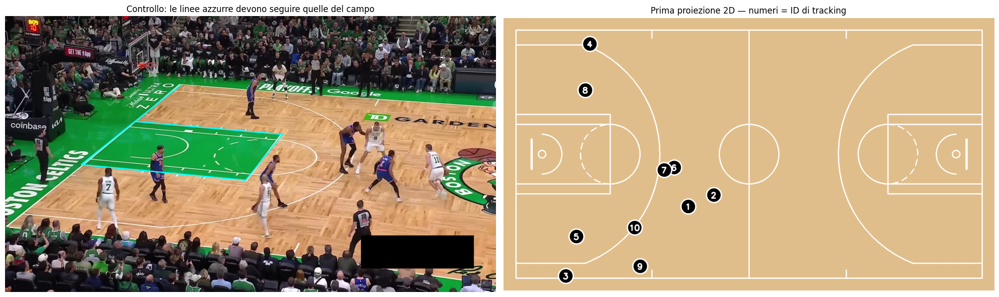

ID 1: x=34.73 ft, y=35.53 ft
ID 2: x=39.92 ft, y=33.24 ft
ID 3: x=10.03 ft, y=49.57 ft
ID 4: x=14.92 ft, y=2.79 ft
ID 5: x=12.21 ft, y=41.59 ft
ID 6: x=31.91 ft, y=27.69 ft
ID 7: x=29.92 ft, y=28.21 ft
ID 8: x=13.98 ft, y=12.09 ft
ID 9: x=25.03 ft, y=47.58 ft
ID 10: x=23.95 ft, y=39.80 ft


In [ ]:
import csv
import matplotlib.pyplot as plt
from sports.basketball import draw_court, draw_points_on_court

# Controllo visivo della geometria.
geometry_overlay = court_frame.copy()

# Segmenti della metà campo visibile:
# linea di fondo e contorno dell'area.
check_segments = [
    (0, 1), (1, 2), (2, 3),
    (2, 9), (9, 11), (11, 3),
]

for a, b in check_segments:
    segment = court_vertices[[a, b]].reshape(-1, 1, 2)
    projected = cv2.perspectiveTransform(
        segment, H_court_to_image
    ).reshape(-1, 2)

    if np.isfinite(projected).all():
        start, end = np.rint(projected).astype(int)
        cv2.line(
            geometry_overlay,
            tuple(start), tuple(end),
            (255, 255, 0), 3,
        )

# Legge le posizioni del primo frame dal tracking salvato.
with open(TRACKS_CSV_PATH, newline="") as file:
    first_frame_tracks = [
        row for row in csv.DictReader(file)
        if int(row["frame"]) == 0
        and int(row["mask_area_px"]) > 0
    ]

if not first_frame_tracks:
    raise RuntimeError("Nessuna posizione disponibile per il primo frame.")

track_ids = [int(row["track_id"]) for row in first_frame_tracks]

image_positions = np.array([
    [float(row["foot_x"]), float(row["foot_y"])]
    for row in first_frame_tracks
], dtype=np.float32)

court_positions = cv2.perspectiveTransform(
    image_positions.reshape(-1, 1, 2),
    H_image_to_court,
).reshape(-1, 2)

if not np.isfinite(court_positions).all():
    raise RuntimeError("La proiezione ha prodotto coordinate non valide.")

court_map = draw_court(config=court_config)
court_map = draw_points_on_court(
    config=court_config,
    xy=court_positions,
    labels=[str(track_id) for track_id in track_ids],
    court=court_map,
)

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

axes[0].imshow(cv2.cvtColor(geometry_overlay, cv2.COLOR_BGR2RGB))
axes[0].set_title("Controllo: le linee azzurre devono seguire quelle del campo")

axes[1].imshow(cv2.cvtColor(court_map, cv2.COLOR_BGR2RGB))
axes[1].set_title("Prima proiezione 2D — numeri = ID di tracking")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

cv2.imwrite(
    str(PROJECT_DIR / "outputs" / "03_geometry_check.jpg"),
    geometry_overlay,
)
cv2.imwrite(
    str(PROJECT_DIR / "outputs" / "04_first_frame_2d.jpg"),
    court_map,
)

for track_id, (x, y) in zip(track_ids, court_positions):
    print(f"ID {track_id}: x={x:.2f} ft, y={y:.2f} ft")

### 24. Generazione della mappa 2D animata

In [ ]:
import csv
import numpy as np
import cv2
from collections import defaultdict, Counter
from tqdm.auto import tqdm

tracks_by_frame = defaultdict(list)

with open(TRACKS_CSV_PATH, newline="") as file:
    for row in csv.DictReader(file):
        tracks_by_frame[int(row["frame"])].append(row)

MAP_RAW_PATH = WORK_DIR / "nba_map_2d_raw.mp4"
MAP_CSV_PATH = PROJECT_DIR / "outputs" / "nba_positions_2d.csv"
GEOMETRY_CSV_PATH = PROJECT_DIR / "outputs" / "nba_geometry_quality.csv"

cap = cv2.VideoCapture(str(VIDEO_PATH))
fps = cap.get(cv2.CAP_PROP_FPS)
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

if not cap.isOpened() or fps <= 0:
    cap.release()
    raise RuntimeError("Video non disponibile o FPS non validi.")

# Scala ridotta per il video della mappa.
MAP_SCALE = 10
MAP_PADDING = 30
base_map = draw_court(
    config=court_config,
    scale=MAP_SCALE,
    padding=MAP_PADDING,
)
map_h, map_w = base_map.shape[:2]

# Dimensioni pari per la successiva conversione H.264.
out_w = map_w + map_w % 2
out_h = map_h + map_h % 2

writer = cv2.VideoWriter(
    str(MAP_RAW_PATH),
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (out_w, out_h),
)

if not writer.isOpened():
    cap.release()
    raise RuntimeError("Impossibile creare il video della mappa.")

geometry_counts = Counter()
processed = 0

try:
    with (
        open(MAP_CSV_PATH, "w", newline="") as positions_file,
        open(GEOMETRY_CSV_PATH, "w", newline="") as geometry_file,
        tqdm(total=total, desc="Proiezione sul campo") as progress,
    ):
        positions_writer = csv.writer(positions_file)
        positions_writer.writerow([
            "frame", "track_id", "x_ft", "y_ft", "status"
        ])

        geometry_writer = csv.writer(geometry_file)
        geometry_writer.writerow([
            "frame", "keypoints", "inliers",
            "median_fit_error_px", "status"
        ])

        while True:
            success, frame = cap.read()
            if not success:
                break

            result = court_model.infer(frame, confidence=0.3)[0]

            H = None
            n_points = 0
            n_inliers = 0
            fit_error = ""
            status = "no_court"

            if result.predictions:
                prediction = max(
                    result.predictions,
                    key=lambda p: p.confidence,
                )

                points = [
                    p for p in prediction.keypoints
                    if p.confidence >= 0.5
                    and 0 <= p.class_id < len(court_vertices)
                ]

                n_points = len(points)
                status = "too_few_points"

                if n_points >= 6:
                    source = court_vertices[
                        [p.class_id for p in points]
                    ]
                    target = np.array(
                        [[p.x, p.y] for p in points],
                        dtype=np.float32,
                    )

                    forward, mask = cv2.findHomography(
                        source, target,
                        cv2.RANSAC, 8.0,
                    )
                    status = "fit_failed"

                    if forward is not None and mask is not None:
                        accepted = mask.ravel().astype(bool)
                        n_inliers = int(accepted.sum())
                        status = "too_few_inliers"

                        if n_inliers >= 6:
                            try:
                                inverse = np.linalg.inv(forward)
                            except np.linalg.LinAlgError:
                                inverse = None

                            if inverse is not None and np.isfinite(inverse).all():
                                projected = cv2.perspectiveTransform(
                                    source.reshape(-1, 1, 2),
                                    forward,
                                ).reshape(-1, 2)

                                errors = np.linalg.norm(
                                    projected - target, axis=1
                                )
                                fit_error = float(
                                    np.median(errors[accepted])
                                )
                                H = inverse
                                status = "fit_available"

            geometry_counts[status] += 1
            geometry_writer.writerow([
                processed, n_points, n_inliers,
                fit_error, status,
            ])

            positions = []
            labels = []

            for row in tracks_by_frame.get(processed, []):
                track_id = int(row["track_id"])
                x, y = "", ""

                if int(row["mask_area_px"]) == 0:
                    player_status = "missing_mask"
                elif H is None:
                    player_status = "missing_geometry"
                else:
                    pixel = np.array([[
                        [float(row["foot_x"]), float(row["foot_y"])]
                    ]], dtype=np.float32)

                    xy = cv2.perspectiveTransform(pixel, H)[0, 0]

                    if not np.isfinite(xy).all():
                        player_status = "invalid_projection"
                    else:
                        x, y = map(float, xy)
                        inside = (
                            0 <= x <= court_config.court_length
                            and 0 <= y <= court_config.court_width
                        )
                        player_status = (
                            "projected" if inside else "outside_court"
                        )

                        # Conserviamo nel CSV anche i punti esterni,
                        # senza forzarli dentro il campo.
                        if inside:
                            positions.append([x, y])
                            labels.append(str(track_id))

                positions_writer.writerow([
                    processed, track_id, x, y, player_status
                ])

            canvas = base_map.copy()

            if positions:
                canvas = draw_points_on_court(
                    config=court_config,
                    xy=np.array(positions, dtype=np.float32),
                    labels=labels,
                    court=canvas,
                    scale=MAP_SCALE,
                    padding=MAP_PADDING,
                    size=15,
                    line_thickness=2,
                )

            message = f"Frame {processed} | ID visibili: {len(positions)}"
            if H is None:
                message += " | GEOMETRIA NON DISPONIBILE"

            cv2.putText(
                canvas, message, (10, 20),
                cv2.FONT_HERSHEY_SIMPLEX, 0.45,
                (0, 0, 0), 1, cv2.LINE_AA,
            )

            canvas = cv2.copyMakeBorder(
                canvas, 0, out_h - map_h, 0, out_w - map_w,
                cv2.BORDER_CONSTANT,
            )

            writer.write(canvas)
            processed += 1
            progress.update(1)

finally:
    cap.release()
    writer.release()

print("Frame elaborati:", processed, "/", total)
print("Esito della geometria:", dict(geometry_counts))
print("Coordinate:", MAP_CSV_PATH)
print("Diagnostica:", GEOMETRY_CSV_PATH)

Proiezione sul campo:   0%|          | 0/165 [00:00<?, ?it/s]

Frame elaborati: 165 / 165
Esito della geometria: {'fit_available': 165}
Coordinate: /content/drive/MyDrive/NBA_Tracking_Project/outputs/nba_positions_2d.csv
Diagnostica: /content/drive/MyDrive/NBA_Tracking_Project/outputs/nba_geometry_quality.csv


### 25. Esportazione del video finale

In [ ]:
import subprocess
import shutil
from IPython.display import Video, display

MAP_LOCAL_PATH = WORK_DIR / "nba_map_2d.mp4"
MAP_FINAL_PATH = PROJECT_DIR / "outputs" / "nba_map_2d.mp4"

conversion = subprocess.run(
    [
        "ffmpeg", "-y", "-loglevel", "error",
        "-i", str(MAP_RAW_PATH),
        "-c:v", "libx264", "-crf", "23",
        "-pix_fmt", "yuv420p",
        "-movflags", "+faststart",
        str(MAP_LOCAL_PATH),
    ],
    capture_output=True,
    text=True,
)

if conversion.returncode != 0:
    raise RuntimeError(conversion.stderr)

shutil.copy2(MAP_LOCAL_PATH, MAP_FINAL_PATH)
display(Video(str(MAP_LOCAL_PATH), embed=True, width=1000))

# Conclusioni e risultati

## Risultati ottenuti

Il notebook ha consentito di implementare una pipeline completa per il rilevamento, il tracking e la ricostruzione spaziale dei giocatori in una clip televisiva NBA.

La sequenza analizzata comprende **165 fotogrammi a 30 FPS**, con dieci giocatori inizializzati mediante YOLO11 e successivamente tracciati attraverso SAM2.

La ricostruzione geometrica viene effettuata individuando i keypoint del campo e stimando una nuova omografia per ciascun fotogramma.

### Risultati quantitativi della baseline v2

| Indicatore | Risultato |
|---|---:|
| Frame elaborati | 165 |
| Giocatori inizializzati | 10 |
| Omografie disponibili | 165/165 |
| Posizioni proiettate sul campo | 1.628 |
| Posizioni fuori campo | 17 |
| Maschere mancanti | 5 |
| Transizioni con velocità apparente superiore a 12 m/s | 86 |

La modifica della procedura di pulizia delle maschere ha ridotto le posizioni fuori campo da **27 nella baseline v1 a 17 nella baseline v2**, corrispondenti a una riduzione di circa il 37%.

## Limitazioni individuate

L'analisi ha evidenziato instabilità nella localizzazione dei giocatori quando le maschere risultano parzialmente occluse o incomplete.

In particolare, il bordo inferiore della maschera non coincide necessariamente con la posizione reale dei piedi. Questo può generare spostamenti artificiali nella rappresentazione 2D.

Le anomalie sono state analizzate tramite controlli temporali, diagnostica delle maschere e confronto del contributo dell'omografia.

## Sviluppi successivi

Il lavoro proseguirà con:

1. Post-processing delle traiettorie mediante rilevamento degli outlier, interpolazione controllata e smoothing.
2. Valutazione quantitativa del detector su un dataset annotato.
3. Valutazione del tracking e della precisione spaziale.
4. Classificazione dei giocatori nelle rispettive squadre.
5. Produzione di traiettorie, heatmap e indicatori tattici.

**Stato del progetto:** pipeline end-to-end implementata e verificata su una clip NBA. La baseline è pronta per le successive fasi di post-processing e valutazione sperimentale.

I risultati riportati descrivono il comportamento del sistema sulla clip analizzata e non costituiscono ancora una valutazione dell'accuratezza su dati indipendenti.